# UCI HAR : classification d'activite (adaptation inter-sujet)

on classe l'activite (6 classes : marche, montee, descente, assis, debout, couche) a partir des 561 features fournies par le dataset. le decoupage d'UCI HAR separe deja les sujets (21 en train, 9 en test), donc source = sujets d'entrainement, cible = sujets de test.

In [68]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import predict, split_har, courbe_apprentissage, courbe_melange, comparer_adapt, barres_adapt

## chargement

In [69]:
data_dir = "../../data/UCI HAR Dataset"

Xs = np.loadtxt(f"{data_dir}/train/X_train.txt")
ys = np.loadtxt(f"{data_dir}/train/y_train.txt").astype(int)
subj_s = np.loadtxt(f"{data_dir}/train/subject_train.txt").astype(int)

Xt = np.loadtxt(f"{data_dir}/test/X_test.txt")
yt = np.loadtxt(f"{data_dir}/test/y_test.txt").astype(int)
subj_t = np.loadtxt(f"{data_dir}/test/subject_test.txt").astype(int)

Xs.shape, Xt.shape, sorted(set(ys))

((7352, 561),
 (2947, 561),
 [np.int64(1),
  np.int64(2),
  np.int64(3),
  np.int64(4),
  np.int64(5),
  np.int64(6)])

## tableaux utilises

le dataset fournit six tableaux, trois pour la source et trois pour la cible : la matrice des 561 features, l'activite a predire, et l'identifiant du sujet. 

les trois tableaux d'un meme domaine sont alignes ligne a ligne, une ligne etant une fenetre de 2.56 secondes.

In [70]:
noms_features = [l.split(" ", 1)[1] for l in open(f"{data_dir}/features.txt").read().strip().split("\n")]
activites = dict(l.split() for l in open(f"{data_dir}/activity_labels.txt").read().strip().split("\n"))

resume = pd.DataFrame([
    ["Xs", Xs.shape, "features source (21 sujets)"],
    ["ys", ys.shape, "activite source"],
    ["subj_s", subj_s.shape, "sujet source"],
    ["Xt", Xt.shape, "features cible (9 sujets)"],
    ["yt", yt.shape, "activite cible"],
    ["subj_t", subj_t.shape, "sujet cible"],
], columns=["tableau", "dimensions", "contenu"])
print(resume.to_string(index=False))
print()
print("activites :", activites)

tableau  dimensions                     contenu
     Xs (7352, 561) features source (21 sujets)
     ys     (7352,)             activite source
 subj_s     (7352,)                sujet source
     Xt (2947, 561)   features cible (9 sujets)
     yt     (2947,)              activite cible
 subj_t     (2947,)                 sujet cible

activites : {'1': 'WALKING', '2': 'WALKING_UPSTAIRS', '3': 'WALKING_DOWNSTAIRS', '4': 'SITTING', '5': 'STANDING', '6': 'LAYING'}


In [71]:
apercu = pd.DataFrame(Xs[:5], columns=noms_features)
apercu.insert(0, "activite", [activites[str(v)] for v in ys[:5]])
apercu.insert(0, "sujet", subj_s[:5])

with pd.option_context("display.max_columns", None):
    display(apercu)

,sujet,activite,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-min()-Z,tBodyAcc-sma(),tBodyAcc-energy()-X,tBodyAcc-energy()-Y,tBodyAcc-energy()-Z,tBodyAcc-iqr()-X,tBodyAcc-iqr()-Y,tBodyAcc-iqr()-Z,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,"tBodyAcc-arCoeff()-X,1","tBodyAcc-arCoeff()-X,2","tBodyAcc-arCoeff()-X,3","tBodyAcc-arCoeff()-X,4","tBodyAcc-arCoeff()-Y,1","tBodyAcc-arCoeff()-Y,2","tBodyAcc-arCoeff()-Y,3","tBodyAcc-arCoeff()-Y,4","tBodyAcc-arCoeff()-Z,1","tBodyAcc-arCoeff()-Z,2","tBodyAcc-arCoeff()-Z,3","tBodyAcc-arCoeff()-Z,4","tBodyAcc-correlation()-X,Y","tBodyAcc-correlation()-X,Z","tBodyAcc-correlation()-Y,Z",tGravityAcc-mean()-X,tGravityAcc-mean()-Y,tGravityAcc-mean()-Z,tGravityAcc-std()-X,tGravityAcc-std()-Y,tGravityAcc-std()-Z,tGravityAcc-mad()-X,tGravityAcc-mad()-Y,tGravityAcc-mad()-Z,tGravityAcc-max()-X,tGravityAcc-max()-Y,tGravityAcc-max()-Z,tGravityAcc-min()-X,tGravityAcc-min()-Y,tGravityAcc-min()-Z,tGravityAcc-sma(),tGravityAcc-energy()-X,tGravityAcc-energy()-Y,tGravityAcc-energy()-Z,tGravityAcc-iqr()-X,tGravityAcc-iqr()-Y,tGravityAcc-iqr()-Z,tGravityAcc-entropy()-X,tGravityAcc-entropy()-Y,tGravityAcc-entropy()-Z,"tGravityAcc-arCoeff()-X,1","tGravityAcc-arCoeff()-X,2","tGravityAcc-arCoeff()-X,3","tGravityAcc-arCoeff()-X,4","tGravityAcc-arCoeff()-Y,1","tGravityAcc-arCoeff()-Y,2","tGravityAcc-arCoeff()-Y,3","tGravityAcc-arCoeff()-Y,4","tGravityAcc-arCoeff()-Z,1","tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4","tGravityAcc-correlation()-X,Y","tGravityAcc-correlation()-X,Z","tGravityAcc-correlation()-Y,Z",tBodyAccJerk-mean()-X,tBodyAccJerk-mean()-Y,tBodyAccJerk-mean()-Z,tBodyAccJerk-std()-X,tBodyAccJerk-std()-Y,tBodyAccJerk-std()-Z,tBodyAccJerk-mad()-X,tBodyAccJerk-mad()-Y,tBodyAccJerk-mad()-Z,tBodyAccJerk-max()-X,tBodyAccJerk-max()-Y,tBodyAccJerk-max()-Z,tBodyAccJerk-min()-X,tBodyAccJerk-min()-Y,tBodyAccJerk-min()-Z,tBodyAccJerk-sma(),tBodyAccJerk-energy()-X,tBodyAccJerk-energy()-Y,tBodyAccJerk-energy()-Z,tBodyAccJerk-iqr()-X,tBodyAccJerk-iqr()-Y,tBodyAccJerk-iqr()-Z,tBodyAccJerk-entropy()-X,tBodyAccJerk-entropy()-Y,tBodyAccJerk-entropy()-Z,"tBodyAccJerk-arCoeff()-X,1","tBodyAccJerk-arCoeff()-X,2","tBodyAccJerk-arCoeff()-X,3","tBodyAccJerk-arCoeff()-X,4","tBodyAccJerk-arCoeff()-Y,1","tBodyAccJerk-arCoeff()-Y,2","tBodyAccJerk-arCoeff()-Y,3","tBodyAccJerk-arCoeff()-Y,4","tBodyAccJerk-arCoeff()-Z,1","tBodyAccJerk-arCoeff()-Z,2","tBodyAccJerk-arCoeff()-Z,3","tBodyAccJerk-arCoeff()-Z,4","tBodyAccJerk-correlation()-X,Y","tBodyAccJerk-correlation()-X,Z","tBodyAccJerk-correlation()-Y,Z",tBodyGyro-mean()-X,tBodyGyro-mean()-Y,tBodyGyro-mean()-Z,tBodyGyro-std()-X,tBodyGyro-std()-Y,tBodyGyro-std()-Z,tBodyGyro-mad()-X,tBodyGyro-mad()-Y,tBodyGyro-mad()-Z,tBodyGyro-max()-X,tBodyGyro-max()-Y,tBodyGyro-max()-Z,tBodyGyro-min()-X,tBodyGyro-min()-Y,tBodyGyro-min()-Z,tBodyGyro-sma(),tBodyGyro-energy()-X,tBodyGyro-energy()-Y,tBodyGyro-energy()-Z,tBodyGyro-iqr()-X,tBodyGyro-iqr()-Y,tBodyGyro-iqr()-Z,tBodyGyro-entropy()-X,tBodyGyro-entropy()-Y,tBodyGyro-entropy()-Z,"tBodyGyro-arCoeff()-X,1","tBodyGyro-arCoeff()-X,2","tBodyGyro-arCoeff()-X,3","tBodyGyro-arCoeff()-X,4","tBodyGyro-arCoeff()-Y,1","tBodyGyro-arCoeff()-Y,2","tBodyGyro-arCoeff()-Y,3","tBodyGyro-arCoeff()-Y,4","tBodyGyro-arCoeff()-Z,1","tBodyGyro-arCoeff()-Z,2","tBodyGyro-arCoeff()-Z,3","tBodyGyro-arCoeff()-Z,4","tBodyGyro-correlation()-X,Y","tBodyGyro-correlation()-X,Z","tBodyGyro-correlation()-Y,Z",tBodyGyroJerk-mean()-X,tBodyGyroJerk-mean()-Y,tBodyGyroJerk-mean()-Z,tBodyGyroJerk-std()-X,tBodyGyroJerk-std()-Y,tBodyGyroJerk-std()-Z,tBodyGyroJerk-mad()-X,tBodyGyroJerk-mad()-Y,tBodyGyroJerk-mad()-Z,tBodyGyroJerk-max()-X,tBodyGyroJerk-max()-Y,tBodyGyroJerk-max()-Z,tBodyGyroJerk-min()-X,tBodyGyroJerk-min()-Y,tBodyGyroJerk-min

## 1. visualisation


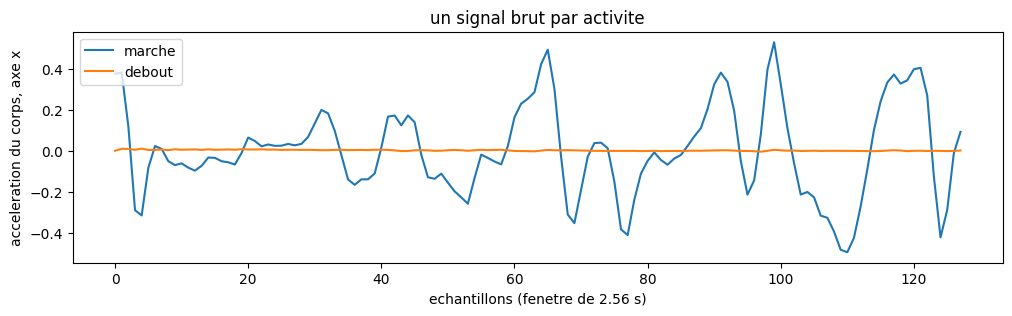

In [72]:
signaux = f"{data_dir}/train/Inertial Signals"
acc_x = np.loadtxt(f"{signaux}/body_acc_x_train.txt")

plt.figure(figsize=(12, 3))
for label, nom in [(1, "marche"), (5, "debout")]:
    idx = np.where(ys == label)[0][0]
    plt.plot(acc_x[idx], label=nom)
plt.xlabel("echantillons (fenetre de 2.56 s)")
plt.ylabel("acceleration du corps, axe x")
plt.title("un signal brut par activite")
plt.legend()
plt.show()

## 2. decoupage par sujet

on decoupe par sujet. les fenetres se recouvrent a 50 pourcent, donc deux fenetres voisines du meme sujet partagent des donnees. on garde 4 sujets source pour le test source, et on separe les 9 sujets cible en 6 pour l'adaptation et 3 pour le test cible.

In [73]:
Xs_train, ys_train, Xs_test, ys_test, Xt_train, yt_train, Xt_test, yt_test = split_har(
    Xs, ys, subj_s, Xt, yt, subj_t)

len(Xs_train), len(Xs_test), len(Xt_train), len(Xt_test)

(5867, 1485, 1848, 1099)

## 3. source vers source et source vers cible

In [74]:
r_source_source = predict("classification", Xs_train, ys_train, Xs_test, ys_test)
r_source_cible = predict("classification", Xs_train, ys_train, Xt_test, yt_test)
r_cible_cible = predict("classification", Xt_train, yt_train, Xt_test, yt_test)

print("source -> source :", round(r_source_source["accuracy"], 3))
print("source -> cible  :", round(r_source_cible["accuracy"], 3))
print("cible  -> cible  :", round(r_cible_cible["accuracy"], 3))

source -> source : 0.966
source -> cible  : 0.969
cible  -> cible  : 0.881


## 4. combien de donnees cible pour un bon modele


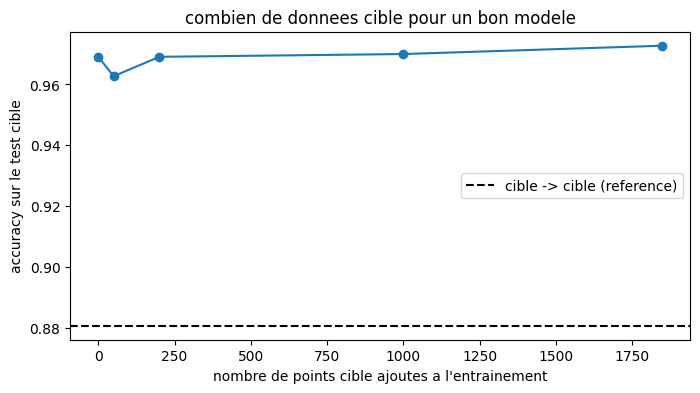

In [75]:
n_values = [0, 50, 200, 1000, len(Xt_train)]
acc_courbe = []
for n in n_values:
    if n == 0:
        X_train, y_train = Xs_train, ys_train
    else:
        X_train = np.vstack([Xs_train, Xt_train[:n]])
        y_train = np.concatenate([ys_train, yt_train[:n]])
    acc_courbe.append(predict("classification", X_train, y_train, Xt_test, yt_test)["accuracy"])

plt.figure(figsize=(8, 4))
plt.plot(n_values, acc_courbe, marker="o")
plt.axhline(r_cible_cible["accuracy"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("accuracy sur le test cible")
plt.title("combien de donnees cible pour un bon modele")
plt.legend()
plt.show()

## 5. courbes d'apprentissage separees (source et cible)

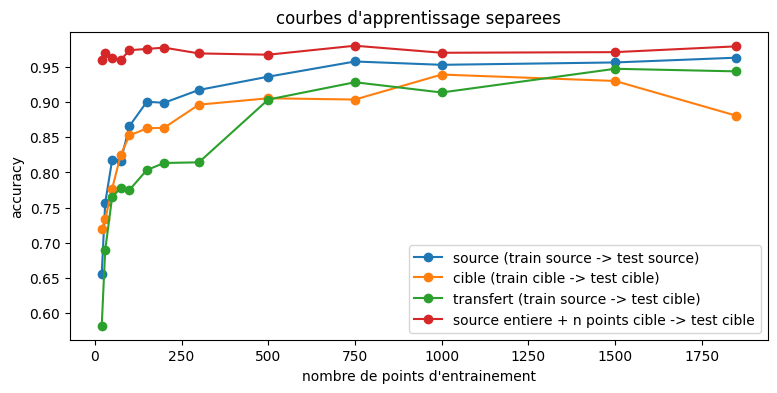

In [76]:
#n_values = [20, 30, 50, 75, 100, 150, 200, 300, 500, 750, 1000, 1500, 1848, 3000, len(Xs_train)]
n_values = [20, 30, 50, 75, 100, 150, 200, 300, 500, 750, 1000, 1500, 1848]
ns_source, acc_source = courbe_apprentissage(Xs_train, ys_train, Xs_test, ys_test, "classification", n_values)
ns_cible, acc_cible = courbe_apprentissage(Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)
ns_transfert, acc_transfert = courbe_apprentissage(Xs_train, ys_train, Xt_test, yt_test, "classification", n_values)
ns_melange, acc_melange = courbe_melange(Xs_train, ys_train, Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, acc_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, acc_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, acc_transfert, marker="o", label="transfert (train source -> test cible)")
plt.plot(ns_melange, acc_melange, marker="o", label="source entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("accuracy")
plt.title("courbes d'apprentissage separees")
plt.legend()
plt.show()

## 6. equilibrage : autant de sujets en source qu'en cible



In [77]:
n_tirages = 5
rng = np.random.default_rng(0)
acc_ss, acc_sc = [], []

for k in range(n_tirages):
    tirage = list(rng.permutation(sorted(set(subj_s)))[:9])
    tr, te = tirage[:6], tirage[6:]
    Xa, ya = Xs[np.isin(subj_s, tr)], ys[np.isin(subj_s, tr)]
    Xb, yb = Xs[np.isin(subj_s, te)], ys[np.isin(subj_s, te)]
    a = predict("classification", Xa, ya, Xb, yb)["accuracy"]
    b = predict("classification", Xa, ya, Xt_test, yt_test)["accuracy"]
    acc_ss.append(a)
    acc_sc.append(b)
    print(f"tirage {k} : {len(Xa)} fenetres   source -> source {a:.3f}   source -> cible {b:.3f}")

print()
print(f"equilibre 9 vs 9, moyenne sur {n_tirages} tirages")
print("  source -> source :", round(float(np.mean(acc_ss)), 3))
print("  source -> cible  :", round(float(np.mean(acc_sc)), 3))
print("  cible  -> cible  :", round(r_cible_cible["accuracy"], 3))

tirage 0 : 2160 fenetres   source -> source 0.875   source -> cible 0.914
tirage 1 : 1984 fenetres   source -> source 0.855   source -> cible 0.924
tirage 2 : 2043 fenetres   source -> source 0.913   source -> cible 0.914
tirage 3 : 2069 fenetres   source -> source 0.903   source -> cible 0.864
tirage 4 : 2052 fenetres   source -> source 0.881   source -> cible 0.908

equilibre 9 vs 9, moyenne sur 5 tirages
  source -> source : 0.885
  source -> cible  : 0.905
  cible  -> cible  : 0.881


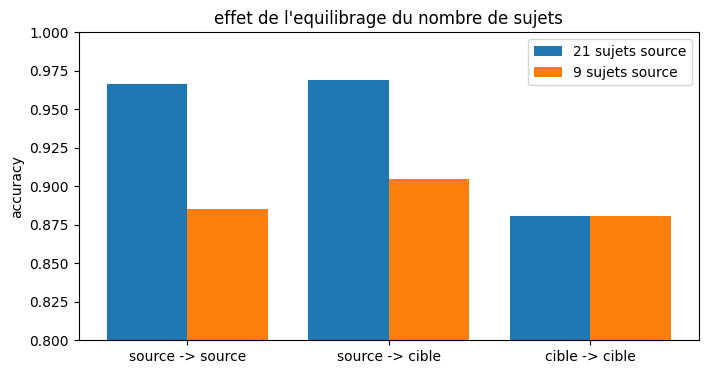

In [78]:
noms = ["source -> source", "source -> cible", "cible -> cible"]
desequilibre = [r_source_source["accuracy"], r_source_cible["accuracy"], r_cible_cible["accuracy"]]
equilibre = [float(np.mean(acc_ss)), float(np.mean(acc_sc)), r_cible_cible["accuracy"]]

x = np.arange(len(noms))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, desequilibre, 0.4, label="21 sujets source")
plt.bar(x + 0.2, equilibre, 0.4, label="9 sujets source")
plt.xticks(x, noms)
plt.ylim(0.8, 1.0)
plt.ylabel("accuracy")
plt.title("effet de l'equilibrage du nombre de sujets")
plt.legend()
plt.show()

source reduite : 2160 fenetres d'entrainement contre 1848 pour la cible


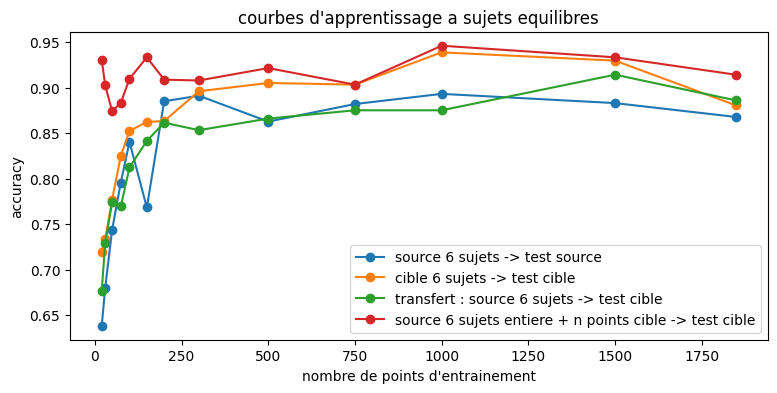

In [79]:
tirage = list(np.random.default_rng(0).permutation(sorted(set(subj_s)))[:9])
Xs9_train, ys9_train = Xs[np.isin(subj_s, tirage[:6])], ys[np.isin(subj_s, tirage[:6])]
Xs9_test, ys9_test = Xs[np.isin(subj_s, tirage[6:])], ys[np.isin(subj_s, tirage[6:])]
print("source reduite :", len(Xs9_train), "fenetres d'entrainement contre", len(Xt_train), "pour la cible")

ns_s9, acc_s9 = courbe_apprentissage(Xs9_train, ys9_train, Xs9_test, ys9_test, "classification", n_values)
ns_c9, acc_c9 = courbe_apprentissage(Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)
ns_t9, acc_t9 = courbe_apprentissage(Xs9_train, ys9_train, Xt_test, yt_test, "classification", n_values)
ns_m9, acc_m9 = courbe_melange(Xs9_train, ys9_train, Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_s9, acc_s9, marker="o", label="source 6 sujets -> test source")
plt.plot(ns_c9, acc_c9, marker="o", label="cible 6 sujets -> test cible")
plt.plot(ns_t9, acc_t9, marker="o", label="transfert : source 6 sujets -> test cible")
plt.plot(ns_m9, acc_m9, marker="o", label="source 6 sujets entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("accuracy")
plt.title("courbes d'apprentissage a sujets equilibres")
plt.legend()
plt.show()

## 16. ADAPT

feature_based,CORAL

instance_based, KMM

parameter_based,  RegularTransferLR

(1848, 6)
(1848, 6)
(1848, 6)
(1848, 6)
(1848, 6)
moyenne sur 5 tirages de 6 sujets source
  sans adaptation                  0.936   (de 0.915 a 0.948)
  CORAL (feature)                  0.602   (de 0.467 a 0.764)
  KMM (instance)                   0.900   (de 0.855 a 0.929)
  RegularTransferLC (parametre)    0.954   (de 0.952 a 0.958)
  cible -> cible                   0.928   (de 0.928 a 0.928)


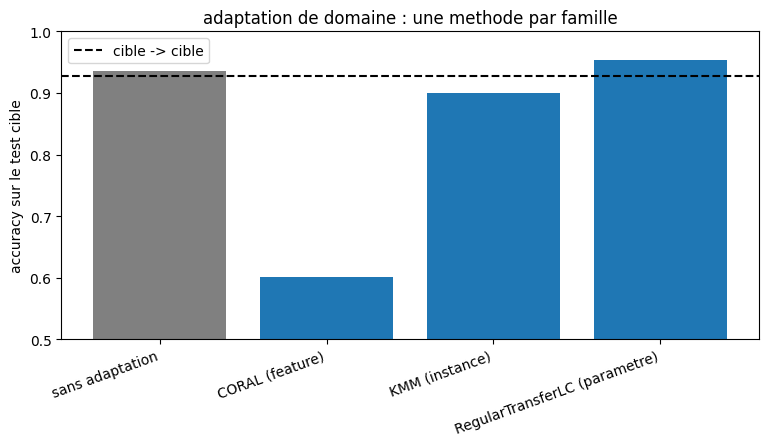

In [80]:
rng_adapt = np.random.default_rng(0)
tables = []
for k in range(n_tirages):
    t = list(rng_adapt.permutation(sorted(set(subj_s)))[:9])
    Xa, ya = Xs[np.isin(subj_s, t[:6])], ys[np.isin(subj_s, t[:6])]
    tables.append(comparer_adapt("classification", Xa, ya, Xt_train, yt_train, Xt_test, yt_test))

resultats = {k: float(np.mean([t[k] for t in tables])) for k in tables[0]}

print(f"moyenne sur {n_tirages} tirages de 6 sujets source")
for k in resultats:
    valeurs = [t[k] for t in tables]
    print(f"  {k:32s} {resultats[k]:.3f}   (de {min(valeurs):.3f} a {max(valeurs):.3f})")

barres_adapt(resultats, "adaptation de domaine : une methode par famille",
             "accuracy sur le test cible", ylim=(0.5, 1.0))

(20, 6)
(50, 6)
(100, 6)
(200, 6)
(300, 6)
(500, 6)
(750, 6)
(1000, 6)
(1500, 6)
(1848, 6)
     20 etiquettes cible : cible seule 0.720   RegularTransferLC 0.867
     50 etiquettes cible : cible seule 0.777   RegularTransferLC 0.864
    100 etiquettes cible : cible seule 0.853   RegularTransferLC 0.888
    200 etiquettes cible : cible seule 0.864   RegularTransferLC 0.919
    300 etiquettes cible : cible seule 0.896   RegularTransferLC 0.919
    500 etiquettes cible : cible seule 0.905   RegularTransferLC 0.944
    750 etiquettes cible : cible seule 0.904   RegularTransferLC 0.944
   1000 etiquettes cible : cible seule 0.939   RegularTransferLC 0.946
   1500 etiquettes cible : cible seule 0.930   RegularTransferLC 0.955
   1848 etiquettes cible : cible seule 0.881   RegularTransferLC 0.955


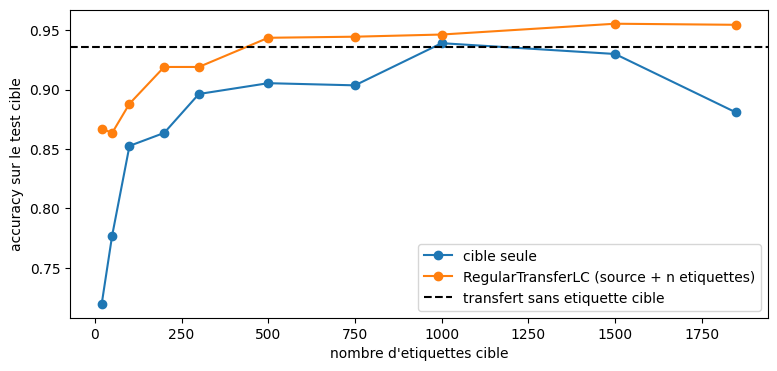

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from adapt.parameter_based import RegularTransferLC

modele_source_har = LogisticRegression(max_iter=5000).fit(Xs9_train, ys9_train)
perm = np.random.default_rng(0).permutation(len(Xt_train))
Xt_m, yt_m = Xt_train[perm], yt_train[perm]

n_etiquettes = [20, 50, 100, 200, 300, 500, 750, 1000, 1500, len(Xt_m)]
acc_seule, acc_adapt = [], []
for n in n_etiquettes:
    acc_seule.append(predict("classification", Xt_m[:n], yt_m[:n], Xt_test, yt_test)["accuracy"])
    m = RegularTransferLC(modele_source_har, lambda_=1.0, random_state=0, verbose=0)
    m.fit(Xt_m[:n], yt_m[:n])
    acc_adapt.append(accuracy_score(yt_test, m.predict(Xt_test)))

for n, a, b in zip(n_etiquettes, acc_seule, acc_adapt):
    print(f"  {n:5d} etiquettes cible : cible seule {a:.3f}   RegularTransferLC {b:.3f}")

plt.figure(figsize=(9, 4))
plt.plot(n_etiquettes, acc_seule, marker="o", label="cible seule")
plt.plot(n_etiquettes, acc_adapt, marker="o", label="RegularTransferLC (source + n etiquettes)")
plt.axhline(resultats["sans adaptation"], color="k", linestyle="--", label="transfert sans etiquette cible")
plt.xlabel("nombre d'etiquettes cible")
plt.ylabel("accuracy sur le test cible")
plt.legend()
plt.show()

## 8. limiter le nb de points source

    2 points cible : cible seule 0.324   avec 200 points source 0.870
    5 points cible : cible seule 0.650   avec 200 points source 0.839
   10 points cible : cible seule 0.554   avec 200 points source 0.858
   15 points cible : cible seule 0.642   avec 200 points source 0.854


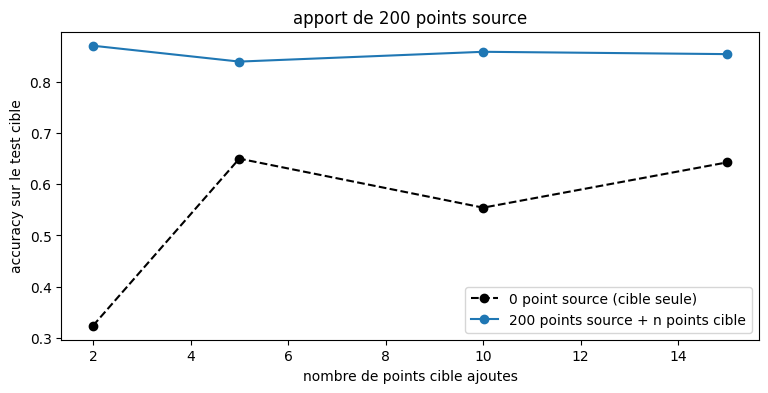

In [82]:
n_source = 200
n_petit = [2, 5, 10, 15]
perm_s = np.random.default_rng(0).permutation(len(Xs9_train))
Xs_m, ys_m = Xs9_train[perm_s][:n_source], ys9_train[perm_s][:n_source]

ns_ref, acc_ref = courbe_apprentissage(Xt_train, yt_train, Xt_test, yt_test, "classification", n_petit)
ns_b, acc_b = courbe_melange(Xs_m, ys_m, Xt_train, yt_train, Xt_test, yt_test, "classification", n_petit)

for n, a, b in zip(n_petit, acc_ref, acc_b):
    print(f"  {n:3d} points cible : cible seule {a:.3f}   avec {n_source} points source {b:.3f}")

plt.figure(figsize=(9, 4))
plt.plot(ns_ref, acc_ref, marker="o", color="k", linestyle="--", label="0 point source (cible seule)")
plt.plot(ns_b, acc_b, marker="o", label=f"{n_source} points source + n points cible")
plt.xlabel("nombre de points cible ajoutes")
plt.ylabel("accuracy sur le test cible")
plt.title(f"apport de {n_source} points source")
plt.legend()
plt.show()